# Projeto 2 — Q-learning e Sarsa no Taxi-v4

**Insper — Inteligência Artificial e Robótica**

Grupo: Gabriel Vivacqua, Rafael Santos, Lucas Watanabe, Joaquim Figueredo

| Arquivo | Conteúdo |
|---|---|
| `QLearning.py` | classe `QLearning` da aula, completa |
| `utils.py` | ambiente, experimentos, avaliação e gráficos |
| `config.py` | hiperparâmetros, seeds e meta (iguais para todo o projeto) |
| `data/` | q-tables em CSV |
| `results/` | rewards, gráficos e métricas |

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy import loadtxt

import config
import utils
from QLearning import QLearning

pd.set_option("display.precision", 2)
print("gymnasium", gym.__version__)

gymnasium 1.4.0


## Introdução

### O ambiente

O **Taxi** é um grid 5×5 com paredes e quatro pontos de embarque e desembarque: **R**, **G**, **Y** e **B** (pontos 0 a 3 no estado). Em cada episódio, o táxi começa numa célula aleatória, o passageiro está num dos pontos e o destino é outro ponto. O agente precisa buscar o passageiro e deixá-lo no destino.

Usamos duas versões do `Taxi-v4` (gymnasium ≥ 1.3), criadas por `utils.make_env`:

- **determinística** (`rainy=False`): cada ação tem sempre o mesmo efeito. É a usada nos itens 1 e 2.
- **chuvosa** (`rainy=True`, ou seja, `is_rainy=True, rainy_probability=0.6`): o táxi vai na direção escolhida com probabilidade 0,6 e escorrega para cada lado com probabilidade 0,2.

No mapa abaixo, o táxi é a célula amarela (verde com o passageiro dentro), o passageiro está no ponto azul e o destino é o ponto magenta. `|` é parede; `:` não bloqueia.

In [2]:
env_texto = gym.make(config.ENV_ID, render_mode="ansi").env
estado, _ = env_texto.reset(seed=0)
print(env_texto.render())
linha, coluna, passageiro, destino = env_texto.unwrapped.decode(estado)
pontos = "RGYB"
print(f"estado {estado}: táxi em (linha {linha}, coluna {coluna}), "
      f"passageiro em {pontos[passageiro]}, destino {pontos[destino]}")
env_texto.close()

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


estado 314: táxi em (linha 3, coluna 0), passageiro em B, destino Y


### Estados, ações e recompensas

O estado é um número de 0 a 499: 25 posições do táxi × 5 situações do passageiro (em R, G, Y, B ou dentro do táxi) × 4 destinos. Desses, 300 podem ser estados iniciais. A q-table tem, portanto, 500 × 6.

| Ação | Significado |
|:---:|---|
| 0 | mover para o sul |
| 1 | mover para o norte |
| 2 | mover para o leste |
| 3 | mover para o oeste |
| 4 | pegar o passageiro (pickup) |
| 5 | deixar o passageiro (dropoff) |

Recompensas:

- **−1** por passo;
- **+20** ao deixar o passageiro no destino, o que encerra o episódio;
- **−10** por pickup ou dropoff ilegal.

Sem ações ilegais, um episódio de $T$ passos rende $21 - T$. Ou seja, maximizar o reward é o mesmo que minimizar o número de passos.

O episódio só termina quando o passageiro é entregue. Como o `.env` remove o limite de 200 passos do `gym.make`, aplicamos `MAX_STEPS = 200` no treino (parâmetro `max_steps` da classe) e na avaliação. Um episódio cortado nesse limite conta como fracasso.

### Algoritmos

Os dois algoritmos usam uma q-table e escolhem ações por **ε-greedy** (`select_action`): com probabilidade ε, uma ação aleatória; senão, a de maior $Q$. Eles diferem no alvo da atualização:

- **Q-learning** (off-policy): $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$. Usa a melhor ação em $s'$, então aprende o valor da política **gulosa**.
- **Sarsa** (on-policy): $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma\, Q(s',a') - Q(s,a)\,]$, em que $a'$ é a ação realmente escolhida. Aprende o valor da política **com exploração**.

`QLearning.py` é a classe da aula com quatro mudanças, marcadas no código: a atualização acima, `rewards_per_episode`, `seed` e `max_steps`. A classe `Sarsa` das próximas etapas deve ter a mesma interface.

### Hiperparâmetros

Os valores de `config.py` valem para todo o projeto, para que Q-learning e Sarsa sejam comparados nas mesmas condições. Seguimos a sugestão da aula de Sarsa.

| Parâmetro | Valor | Justificativa |
|---|---|---|
| α | 0,1 | Atualizações pequenas e estáveis. Precisa servir também no chuvoso, em que cada transição é ruidosa. |
| γ | 0,99 | O +20 só vem no fim, até 18 passos depois. Com γ perto de 1, ele chega ao início do episódio sem perder muito ($0{,}99^{18} \approx 0{,}83$). |
| ε | 0,1 fixo (ε_min = 0,1, decaimento 1) | A exploração é a mesma durante todo o treino, que é quando Q-learning e Sarsa se diferenciam. Como a q-table começa zerada e quase todo reward é negativo, ações não testadas parecem melhores, e o agente explora mesmo com ε baixo. |
| Episódios | 5000 | O determinístico estabiliza perto do episódio 2000; sobra margem para o chuvoso. |
| `MAX_STEPS` | 200 | Igual ao limite oficial do Taxi-v4. A política ótima precisa de no máximo 18 passos. |
| Execuções | 5 (seeds 0 a 4) | Média e desvio padrão entre execuções, com resultados reprodutíveis. |
| Avaliação | 100 episódios, seed 1000 | Todas as q-tables enfrentam os mesmos estados iniciais. |

### Meta de reward

Como o modelo do ambiente é conhecido (`env.unwrapped.P`), dá para calcular a política ótima exatamente com `utils.optimal_q_table` (iteração de valor). Já `utils.expected_reward` calcula o reward médio esperado de uma q-table, com ou sem exploração, sem precisar simular.

In [3]:
env = utils.make_env(rainy=False)
q_otima = utils.optimal_q_table(env)
reward_otimo = utils.expected_reward(q_otima, env)
reward_otimo_eps = utils.expected_reward(q_otima, env, epsilon=config.EPSILON)
iniciais = np.flatnonzero(env.unwrapped.initial_state_distrib > 0)
v_iniciais = q_otima.max(axis=1)[iniciais]
env.close()

print(f"Estados iniciais possíveis:          {len(iniciais)}")
print(f"Reward médio da política ótima:      {reward_otimo:+.2f}  (= {21 - reward_otimo:.2f} passos em média)")
print(f"Pior / melhor estado inicial:        {v_iniciais.min():+.0f} / {v_iniciais.max():+.0f}  "
      f"({21 - v_iniciais.min():.0f} / {21 - v_iniciais.max():.0f} passos)")
print(f"Política ótima com ε = {config.EPSILON} (treino): {reward_otimo_eps:+.2f}")
print(f"reward_threshold do Gymnasium:       {gym.spec(config.ENV_ID).reward_threshold}")

Estados iniciais possíveis:          300
Reward médio da política ótima:      +7.93  (= 13.07 passos em média)
Pior / melhor estado inicial:        +3 / +15  (18 / 6 passos)
Política ótima com ε = 0.1 (treino): +2.41
reward_threshold do Gymnasium:       8


**Meta: reward médio de pelo menos +7,0 por episódio no ambiente determinístico, usando a política gulosa** (`config.META_REWARD`).

- O ótimo é **+7,93** (≈ 13 passos), dentro dos "+7 a +8" esperados para o Taxi. A meta aceita, em média, menos de um passo a mais que o ótimo.
- O `reward_threshold = 8` do Gymnasium fica acima do ótimo, então não serve como meta.
- **Curva de treino:** com ε = 0,1, cerca de uma ação por episódio é aleatória, e cada uma custa uns 4 pontos (um pickup ou dropoff ilegal custa 10). Por isso, mesmo agindo de forma ótima, o reward esperado durante o treino é só **+2,41**. A curva do item 1 deve ser comparada com esse teto; a meta é verificada no item 2, sem exploração.

## Item 1 — Treino do Q-learning no ambiente determinístico

Cinco execuções de 5000 episódios (seeds 0 a 4), registrando o reward de cada episódio. `run_experiments` salva as q-tables em `data/q-table-qlearning-det-run{i}.csv` e os rewards (5 × 5000) em `results/rewards-qlearning-det.npy`.

In [4]:
rewards_q_det = utils.run_experiments(QLearning, rainy=False)

qlearning-det run0 (seed 0): reward médio nos últimos 100 episódios = +2.47


qlearning-det run1 (seed 1): reward médio nos últimos 100 episódios = +2.68


qlearning-det run2 (seed 2): reward médio nos últimos 100 episódios = +2.92


qlearning-det run3 (seed 3): reward médio nos últimos 100 episódios = +2.39


qlearning-det run4 (seed 4): reward médio nos últimos 100 episódios = +2.32


Média móvel de 100 episódios em alguns pontos do treino, média dos últimos 1000 episódios e reward esperado exato de cada q-table final com ε = 0,1.

In [5]:
janela = config.JANELA_MEDIA_MOVEL
media_movel = utils.moving_average(rewards_q_det, janela)

env = utils.make_env(rainy=False)
q_tables = [loadtxt(utils.q_table_path("qlearning-det", i), delimiter=",") for i in range(config.N_RUNS)]

marcos = [100, 500, 1000, 1500, 2000, 3000, 5000]
resumo_treino = pd.DataFrame(
    {f"ep. {ep}": media_movel[:, ep - janela] for ep in marcos},
    index=[f"run{i}" for i in range(config.N_RUNS)],
)
resumo_treino["últimos 1000 ep."] = rewards_q_det[:, -1000:].mean(axis=1)
resumo_treino["esperado com ε = 0,1"] = [
    utils.expected_reward(q, env, epsilon=config.EPSILON) for q in q_tables
]
resumo_treino.loc["média"] = resumo_treino.mean()
env.close()
resumo_treino

,ep. 100,ep. 500,ep. 1000,ep. 1500,ep. 2000,ep. 3000,ep. 5000,últimos 1000 ep.,"esperado com ε = 0,1"
run0,-319.18,-101.99,-11.91,1.10,0.87,2.75,2.47,2.00,2.34
run1,-316.53,-93.40,-12.42,-0.83,2.27,1.56,2.68,2.28,2.33
run2,-312.19,-94.92,-15.38,0.64,2.05,2.30,2.92,2.15,2.35
run3,-312.59,-83.54,-15.06,0.68,1.23,2.92,2.39,2.15,2.35
run4,-308.36,-85.99,-13.98,0.80,1.61,1.75,2.32,2.53,2.36
média,-313.77,-91.97,-13.75,0.48,1.61,2.26,2.56,2.22,2.35


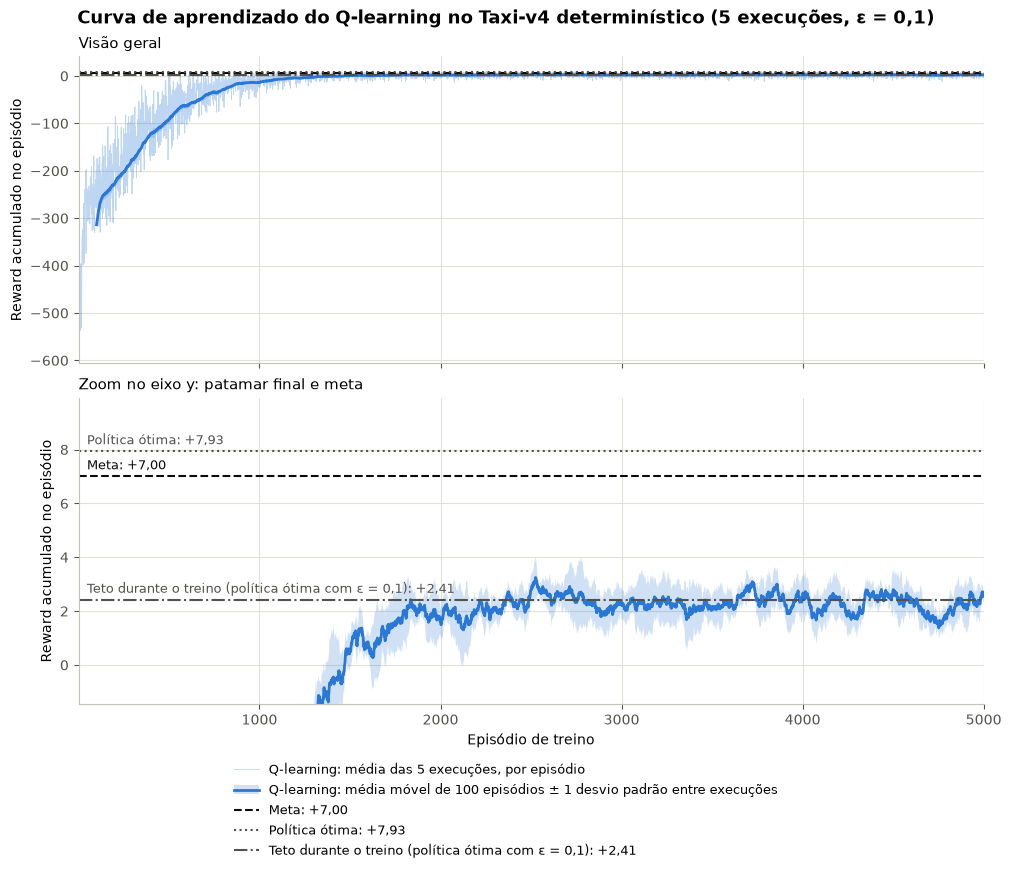

In [6]:
fig = utils.plot_learning_curves(
    {"Q-learning": rewards_q_det},
    meta=config.META_REWARD,
    titulo="Curva de aprendizado do Q-learning no Taxi-v4 determinístico (5 execuções, ε = 0,1)",
    arquivo="curva-qlearning-det.png",
    referencias={
        f"Política ótima: {reward_otimo:+.2f}".replace(".", ","): reward_otimo,
        f"Teto durante o treino (política ótima com ε = 0,1): {reward_otimo_eps:+.2f}".replace(".", ","):
            reward_otimo_eps,
    },
)
plt.show()

**Análise.**

- **Início.** Sem conhecimento, os 10 primeiros episódios rendem em média −521 (muitos passos e muitas ações ilegais).
- **Aprendizado.** A média móvel sobe rápido no começo (−314 no episódio 100, −14 no 1000) e depois mais devagar (+1,6 no 2000).
- **Patamar.** A partir do episódio ~2000, a curva fica em torno de +2,2, quase em cima do teto de +2,41. O agente já age de forma quase ótima; o que o separa da meta é a exploração de 10 %. O reward esperado exato de cada q-table com ε = 0,1 (+2,33 a +2,36) confirma isso.
- **Consistência.** A faixa entre execuções é estreita: as cinco seeds chegam ao mesmo resultado.
- **Meta.** Não é atingida no treino, como esperado. A verificação é no item 2.

## Item 2 — Avaliação da q-table no ambiente determinístico

Como na aula, carregamos a q-table com `loadtxt` e rodamos 100 episódios com a **política gulosa** (sem exploração), com o mesmo limite de 200 passos. Primeiro, a q-table da execução 0:

In [7]:
q_table = loadtxt("data/q-table-qlearning-det-run0.csv", delimiter=",")
env = utils.make_env(rainy=False)
timesteps, rewards, sucessos = utils.evaluate(q_table, env, n=config.N_EVAL, seed=config.SEED_EVAL)
env.close()
utils.print_evaluation(timesteps, rewards, sucessos)

Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%


Agora as 5 q-tables, com `utils.evaluate_runs` (que também usa `loadtxt`). Todas usam a mesma seed, então enfrentam os mesmos 100 estados iniciais. O resultado é salvo em `results/avaliacao-qlearning-det.csv`; a linha `todas` junta os 500 episódios.

In [8]:
res_eval, tabela_eval = utils.evaluate_runs("qlearning-det", rainy=False)
tabela_eval

--- qlearning-det run0 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%
--- qlearning-det run1 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%
--- qlearning-det run2 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%
--- qlearning-det run3 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%


--- qlearning-det run4 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%


,timesteps_media,timesteps_dp,reward_media,reward_dp,taxa_sucesso
q-table,,,,,
run0,12.94,2.59,8.06,2.59,1.0
run1,12.94,2.59,8.06,2.59,1.0
run2,12.94,2.59,8.06,2.59,1.0
run3,12.94,2.59,8.06,2.59,1.0
run4,12.94,2.59,8.06,2.59,1.0
todas,12.94,2.59,8.06,2.59,1.0


Comparação com a política ótima nos mesmos 100 estados, e reward esperado exato em todos os 300 estados iniciais:

In [9]:
env = utils.make_env(rainy=False)
ts_otimo, _, _ = utils.evaluate(q_otima, env, n=config.N_EVAL, seed=config.SEED_EVAL)
comparacao = pd.DataFrame({
    "timesteps médios (100 ep.)": res_eval["timesteps"].mean(axis=1),
    "passos a mais que o ótimo (100 ep.)": (res_eval["timesteps"] - np.array(ts_otimo)).sum(axis=1),
    "reward esperado exato (300 estados)": [utils.expected_reward(q, env) for q in q_tables],
}, index=[f"run{i}" for i in range(config.N_RUNS)])
comparacao.loc["política ótima"] = [np.mean(ts_otimo), 0, reward_otimo]
env.close()
comparacao.style.format({"timesteps médios (100 ep.)": "{:.2f}",
                         "passos a mais que o ótimo (100 ep.)": "{:.0f}",
                         "reward esperado exato (300 estados)": "{:+.3f}"})

,timesteps médios (100 ep.),passos a mais que o ótimo (100 ep.),reward esperado exato (300 estados)
run0,12.94,0,+7.930
run1,12.94,0,+7.923
run2,12.94,0,+7.930
run3,12.94,0,+7.923
run4,12.94,0,+7.930
política ótima,12.94,0,+7.930


**Análise.**

- **Resultado.** As 5 q-tables levam **12,94 ± 2,59 timesteps** por episódio, com reward médio de **+8,06** e **100 % de sucesso**. **A meta de +7,0 foi atingida.**
- **É a política ótima.** Nos mesmos 100 estados, a política ótima também usa 12,94 passos, e nenhuma q-table gastou um passo a mais. Considerando os 300 estados iniciais possíveis, três q-tables são exatamente ótimas e as outras duas erram em um único estado cada (2 passos a mais), que não estava entre os 100 sorteados.
- **Por que +8,06 e não +7,93?** Os 100 estados sorteados são um pouco mais fáceis que a média; a própria política ótima obtém +8,06 neles.
- **Desvio padrão.** Ambiente e política são determinísticos, então o desvio vem só das distâncias diferentes em cada estado inicial, e não de instabilidade do agente. O desvio do reward é igual porque o reward é exatamente $21 - T$.
- **Treino × avaliação.** O mesmo agente obtinha ≈ +2,2 no treino e obtém +8,06 sem exploração. A diferença é o custo da exploração, que não atrapalha o que o Q-learning aprende; no Sarsa isso pode mudar, e é o que as próximas etapas vão comparar.

## Item 3 — Comparação entre Q-learning e Sarsa

Os dois agentes usam o ambiente determinístico, as mesmas cinco seeds e os mesmos hiperparâmetros. O Sarsa é treinado abaixo; os arquivos gerados recebem o prefixo `sarsa-det`.

In [10]:
from Sarsa import Sarsa

rewards_sarsa_det = utils.run_experiments(Sarsa, rainy=False, prefix="sarsa-det")

sarsa-det run0 (seed 0): reward médio nos últimos 100 episódios = +2.10


sarsa-det run1 (seed 1): reward médio nos últimos 100 episódios = +2.76


sarsa-det run2 (seed 2): reward médio nos últimos 100 episódios = +2.39


sarsa-det run3 (seed 3): reward médio nos últimos 100 episódios = +3.39


sarsa-det run4 (seed 4): reward médio nos últimos 100 episódios = +2.89


In [11]:
res_eval_sarsa, tabela_eval_sarsa = utils.evaluate_runs("sarsa-det", rainy=False)
tabela_eval_sarsa

--- sarsa-det run0 (100 episódios)
Average actions taken: 12.81
Standard deviation actions taken: 2.63
Average reward: 8.19
Standard deviation reward: 2.63
Success rate: 100%
--- sarsa-det run1 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%


--- sarsa-det run2 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%
--- sarsa-det run3 (100 episódios)
Average actions taken: 12.94
Standard deviation actions taken: 2.59
Average reward: 8.06
Standard deviation reward: 2.59
Success rate: 100%


--- sarsa-det run4 (100 episódios)
Average actions taken: 14.66
Standard deviation actions taken: 18.81
Average reward: 6.13
Standard deviation reward: 20.88
Success rate: 99%


,timesteps_media,timesteps_dp,reward_media,reward_dp,taxa_sucesso
q-table,,,,,
run0,12.81,2.63,8.19,2.63,1.00
run1,12.94,2.59,8.06,2.59,1.00
run2,12.94,2.59,8.06,2.59,1.00
run3,12.94,2.59,8.06,2.59,1.00
run4,14.66,18.81,6.13,20.88,0.99
todas,13.26,8.76,7.70,9.66,1.00


### Curvas de aprendizado

As curvas mostram a média por episódio, a média móvel de 100 episódios e ±1 desvio padrão entre execuções. A linha horizontal é a meta de reward +7,0.

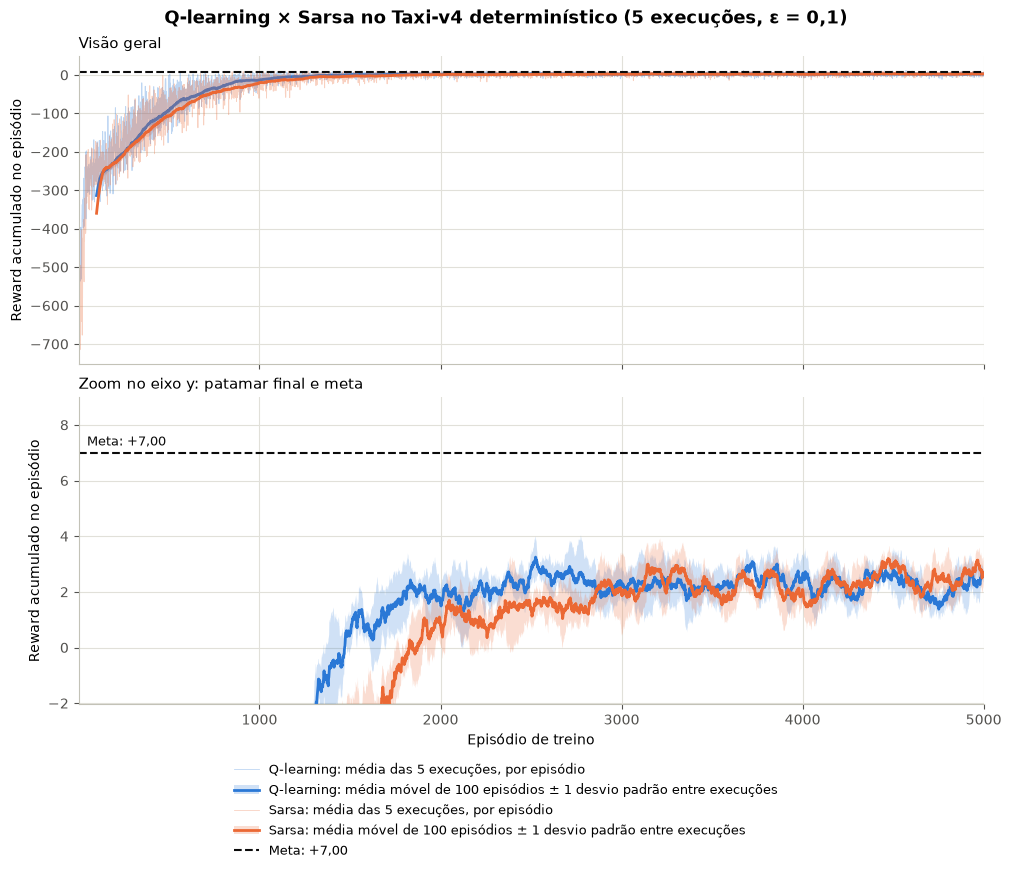

In [12]:
rewards_q_det = np.load(utils.rewards_path("qlearning-det"))
fig = utils.plot_learning_curves(
    {"Q-learning": rewards_q_det, "Sarsa": rewards_sarsa_det},
    meta=config.META_REWARD,
    titulo="Q-learning × Sarsa no Taxi-v4 determinístico (5 execuções, ε = 0,1)",
    arquivo="curva-comparacao-det.png",
)
plt.show()

### Tabela comparativa

“Episódio até atingir a meta” é definido como o primeiro episódio com reward do episódio ≥ `META_REWARD`. A variância é a variância amostral (`ddof=1`) desses cinco episódios, portanto mede a diferença de velocidade entre execuções. Timesteps e reward são calculados nos 500 episódios de avaliação (100 por q-table), sem exploração.

In [13]:
def primeiro_ep_meta(rewards):
    return np.array([
        np.flatnonzero(run >= config.META_REWARD)[0] + 1
        if np.any(run >= config.META_REWARD) else np.nan
        for run in rewards
    ])

ep_meta_q = primeiro_ep_meta(rewards_q_det)
ep_meta_s = primeiro_ep_meta(rewards_sarsa_det)

def linha_comparacao(nome, ep_meta, tabela):
    avaliacao = tabela.loc["todas"]
    return {
        "agente": nome,
        "episódios até a meta (média)": np.nanmean(ep_meta),
        "variância entre execuções": np.nanvar(ep_meta, ddof=1),
        "timesteps médios ± desvio": f"{avaliacao.timesteps_media:.2f} ± {avaliacao.timesteps_dp:.2f}",
        "reward médio": avaliacao.reward_media,
    }

tabela_comparacao = pd.DataFrame([
    linha_comparacao("Q-learning", ep_meta_q, tabela_eval),
    linha_comparacao("Sarsa", ep_meta_s, tabela_eval_sarsa),
]).set_index("agente")
tabela_comparacao.style.format({
    "episódios até a meta (média)": "{:.1f}",
    "variância entre execuções": "{:.1f}",
    "reward médio": "{:+.2f}",
})

,episódios até a meta (média),variância entre execuções,timesteps médios ± desvio,reward médio
agente,,,,
Q-learning,165.6,4319.8,12.94 ± 2.59,+8.06
Sarsa,259.8,8212.2,13.26 ± 8.76,+7.70


### Discussão

Nos dados obtidos, o Q-learning atingiu a meta pela primeira vez, em média, no episódio **165,6**, contra **259,8** do Sarsa. A variância dos episódios de chegada foi **4.319,8** no Q-learning e **8.212,2** no Sarsa, indicando que o Sarsa foi menos consistente entre as cinco execuções. Como a meta é medida em um episódio isolado, ela é uma medida de velocidade inicial e deve ser interpretada junto com a curva e a avaliação final.

Na avaliação gulosa, o Q-learning obteve **12,94 ± 2,59 timesteps** e reward médio **+8,06**; o Sarsa obteve **13,26 ± 8,76 timesteps** e reward médio **+7,70**. Portanto, neste conjunto de seeds, o Q-learning foi mais eficiente no aprendizado e teve melhor desempenho final. O desvio maior do Sarsa está associado principalmente à execução 4, que ainda apresentou um episódio sem sucesso na avaliação.

A diferença é coerente com os alvos dos métodos. O Q-learning é **off-policy**: atualiza usando `max_a Q(s', a)`, isto é, aprende como se a próxima ação fosse a melhor mesmo quando a política de comportamento explorou outra ação. O Sarsa é **on-policy**: atualiza usando o valor da ação `a'` realmente escolhida por `select_action(next_state)`, incluindo a exploração com ε = 0,1. Assim, o Sarsa incorpora o custo e o risco da exploração no valor aprendido. Por isso ele é o método mais **conservador**: tende a evitar trajetórias cujo desempenho cai muito quando uma ação exploratória acontece, enquanto o Q-learning é mais otimista em relação à política gulosa final.

## Item 4 — Generalização para o ambiente com chuva

As q-tables treinadas no ambiente determinístico são carregadas com `loadtxt` e avaliadas sem exploração (`argmax`) em 100 episódios por execução. Repetimos a avaliação nas cinco q-tables de cada algoritmo, tanto no ambiente determinístico quanto no ambiente com chuva (`is_rainy=True`, `rainy_probability=0,6`). O episódio é considerado limitado quando chega a `MAX_STEPS` sem terminar.

In [14]:
def avaliar_item4(algoritmo, rainy):
    """Avalia as q-tables determinísticas no ambiente escolhido."""
    prefixo = f"{algoritmo}-{'rainy' if rainy else 'det'}"
    timesteps, rewards, sucessos, no_limite = [], [], [], []

    for run in range(config.N_RUNS):
        q_table = loadtxt(
            config.DATA_DIR / f"q-table-{algoritmo}-det-run{run}.csv",
            delimiter=",",
        )
        env = utils.make_env(rainy=rainy)
        ts, rw, ok = utils.evaluate(
            q_table,
            env,
            n=config.N_EVAL,
            max_steps=config.MAX_STEPS,
            seed=config.SEED_EVAL,
        )
        env.close()

        ts = np.asarray(ts, dtype=int)
        rw = np.asarray(rw, dtype=float)
        ok = np.asarray(ok, dtype=bool)
        timesteps.extend(ts)
        rewards.extend(rw)
        sucessos.extend(ok)
        no_limite.extend((ts >= config.MAX_STEPS) & ~ok)

    dados = {
        "timesteps": np.asarray(timesteps, dtype=int),
        "rewards": np.asarray(rewards, dtype=float),
        "sucesso": np.asarray(sucessos, dtype=bool),
        "limite": np.asarray(no_limite, dtype=bool),
    }
    np.savez(config.RESULTS_DIR / f"avaliacao-{prefixo}.npz", **dados)
    return dados


dados_item4 = {}
for algoritmo in ("qlearning", "sarsa"):
    for rainy in (False, True):
        dados_item4[(algoritmo, rainy)] = avaliar_item4(algoritmo, rainy)

linhas_item4 = []
for (algoritmo, rainy), dados in dados_item4.items():
    linhas_item4.append({
        "algoritmo": "Q-learning" if algoritmo == "qlearning" else "Sarsa",
        "ambiente": "Com chuva" if rainy else "Determinístico",
        "timesteps médios": dados["timesteps"].mean(),
        "desvio padrão dos timesteps": dados["timesteps"].std(),
        "taxa de sucesso": dados["sucesso"].mean(),
        "reward médio": dados["rewards"].mean(),
        "episódios no limite": int(dados["limite"].sum()),
    })

tabela_item4 = pd.DataFrame(linhas_item4)
tabela_item4.to_csv(config.RESULTS_DIR / "avaliacao-item4.csv", index=False)
tabela_item4.style.format({
    "timesteps médios": "{:.2f}",
    "desvio padrão dos timesteps": "{:.2f}",
    "taxa de sucesso": "{:.1%}",
    "reward médio": "{:.2f}",
})

,algoritmo,ambiente,timesteps médios,desvio padrão dos timesteps,taxa de sucesso,reward médio,episódios no limite
0,Q-learning,Determinístico,12.94,2.59,100.0%,8.06,0
1,Q-learning,Com chuva,25.58,14.12,99.6%,-4.67,2
2,Sarsa,Determinístico,13.26,8.76,99.8%,7.70,1
3,Sarsa,Com chuva,28.11,24.70,98.2%,-7.49,9


### Distribuição dos timesteps

O gráfico abaixo compara diretamente a distribuição do número de ações até o término (ou até o limite) nos dois ambientes.

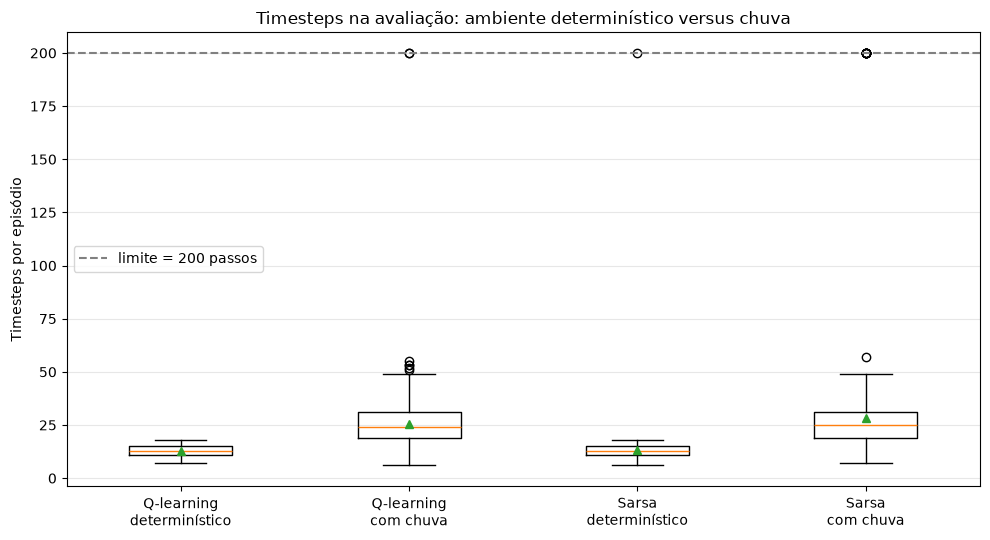

In [15]:
grupos = [
    dados_item4[("qlearning", False)]["timesteps"],
    dados_item4[("qlearning", True)]["timesteps"],
    dados_item4[("sarsa", False)]["timesteps"],
    dados_item4[("sarsa", True)]["timesteps"],
]
rotulos = ["Q-learning\ndeterminístico", "Q-learning\ncom chuva",
           "Sarsa\ndeterminístico", "Sarsa\ncom chuva"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.boxplot(grupos, tick_labels=rotulos, showmeans=True)
ax.axhline(config.MAX_STEPS, color="gray", linestyle="--",
           label=f"limite = {config.MAX_STEPS} passos")
ax.set_title("Timesteps na avaliação: ambiente determinístico versus chuva")
ax.set_ylabel("Timesteps por episódio")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / "boxplot-timesteps-item4.png", dpi=150)
plt.show()


### Discussão

A q-table treinada no ambiente determinístico continua parcialmente eficaz com chuva, mas perde bastante desempenho. No Q-learning, a média passou de **12,94 ± 2,59** para **25,58 ± 14,12 timesteps**, o reward médio caiu de **+8,06** para **−4,67**, e houve **2 episódios limitados** em 500. No Sarsa, passou de **13,26 ± 8,76** para **28,11 ± 24,70 timesteps**, o reward médio caiu de **+7,70** para **−7,49**, com **9 episódios limitados**. As taxas de sucesso foram, respectivamente, 100,0% e 99,6% para Q-learning, e 99,8% e 98,2% para Sarsa.

A aleatoriedade quebra a hipótese implícita da política determinística: uma ação que antes levava com certeza ao próximo estado desejado pode produzir outro deslocamento. Assim, a sequência de ações codificada na q-table deixa de ser confiável, gerando desvios, mais penalidades e trajetórias mais longas. O Q-learning foi mais robusto neste experimento: teve menor aumento de timesteps, reward menos negativo, maior taxa de sucesso e menos episódios no limite. Isso não significa que a q-table tenha aprendido a política ótima chuvosa; ela apenas generalizou melhor, pois nenhum dos dois algoritmos foi treinado com transições aleatórias.

## Item 5 — Treino direto no ambiente com chuva

Agora os dois agentes aprendem desde o início no ambiente não determinístico (`rainy=True`). São cinco execuções de cada, com as mesmas seeds e os mesmos hiperparâmetros de `config.py`. Os arquivos gerados têm os prefixos `qlearning-rainy` e `sarsa-rainy`.

In [16]:
rewards_q_rainy = utils.run_experiments(QLearning, rainy=True)
rewards_sarsa_rainy = utils.run_experiments(Sarsa, rainy=True)

qlearning-rainy run0 (seed 0): reward médio nos últimos 100 episódios = -16.35


qlearning-rainy run1 (seed 1): reward médio nos últimos 100 episódios = -15.04


qlearning-rainy run2 (seed 2): reward médio nos últimos 100 episódios = -18.23


qlearning-rainy run3 (seed 3): reward médio nos últimos 100 episódios = -19.67


qlearning-rainy run4 (seed 4): reward médio nos últimos 100 episódios = -16.72


sarsa-rainy run0 (seed 0): reward médio nos últimos 100 episódios = -19.59


sarsa-rainy run1 (seed 1): reward médio nos últimos 100 episódios = -25.03


sarsa-rainy run2 (seed 2): reward médio nos últimos 100 episódios = -23.22


sarsa-rainy run3 (seed 3): reward médio nos últimos 100 episódios = -24.07


sarsa-rainy run4 (seed 4): reward médio nos últimos 100 episódios = -22.34


### Referências no ambiente com chuva

Como no início do relatório, o modelo do ambiente permite calcular a política ótima exata, agora com as transições da chuva.

In [17]:
env_chuva = utils.make_env(rainy=True)
q_otima_chuva = utils.optimal_q_table(env_chuva)
reward_otimo_chuva = utils.expected_reward(q_otima_chuva, env_chuva)
reward_otimo_chuva_eps = utils.expected_reward(q_otima_chuva, env_chuva, epsilon=config.EPSILON)
reward_q_det_chuva = utils.expected_reward(q_otima, env_chuva)
env_chuva.close()

print(f"Reward médio da política ótima na chuva:      {reward_otimo_chuva:+.2f}")
print(f"Política ótima com ε = {config.EPSILON} (teto no treino):   {reward_otimo_chuva_eps:+.2f}")
print(f"Política ótima do determinístico, na chuva:   {reward_q_det_chuva:+.2f}")

Reward médio da política ótima na chuva:      -3.96
Política ótima com ε = 0.1 (teto no treino):   -15.07
Política ótima do determinístico, na chuva:   -4.23


**A meta de +7,0 não é alcançável com chuva:** ela foi definida para o ambiente determinístico, e nem a política ótima passa de **−3,96** com chuva. Mantemos a meta no gráfico para comparação, mas o que mede o desempenho aqui são as duas referências: −3,96 sem exploração e −15,07 com ε = 0,1, o teto da curva de treino.

Também vale notar que a política ótima do ambiente determinístico já rende −4,23 com chuva, só 0,26 abaixo do ótimo. Ou seja, neste ambiente há pouco a ganhar com uma política específica para a chuva.

### Curvas de aprendizado

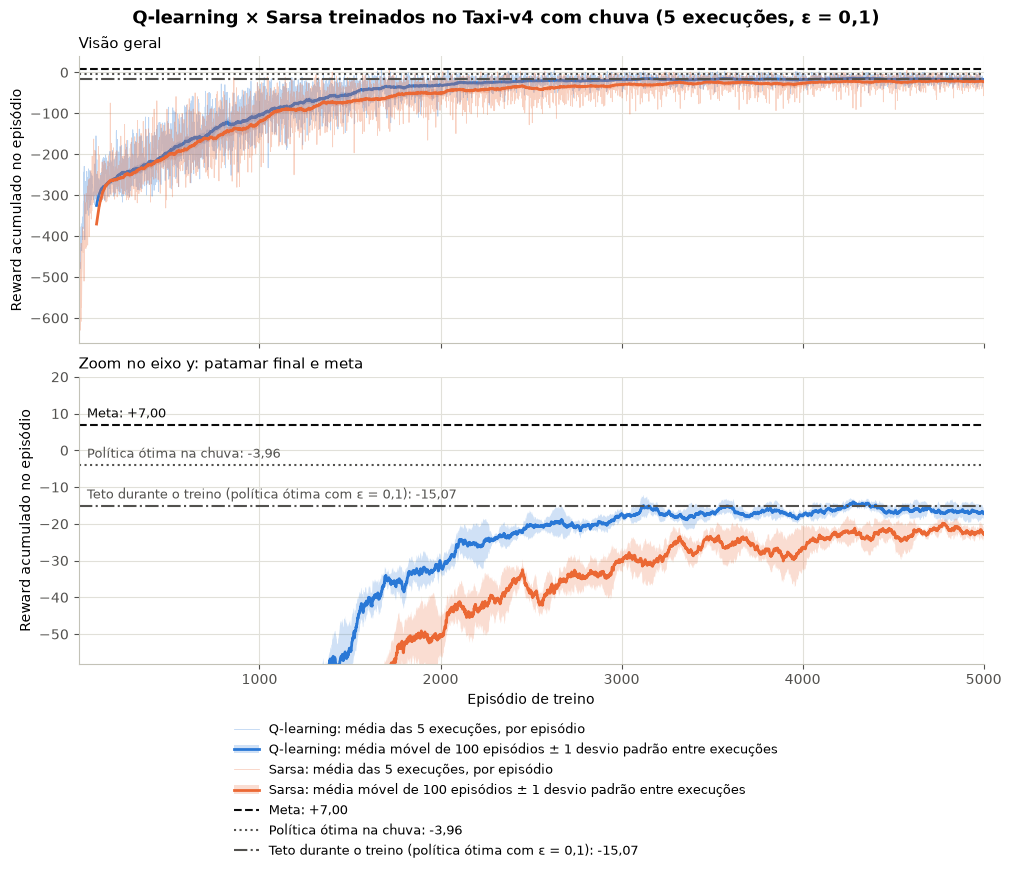

In [18]:
fig = utils.plot_learning_curves(
    {"Q-learning": rewards_q_rainy, "Sarsa": rewards_sarsa_rainy},
    meta=config.META_REWARD,
    titulo="Q-learning × Sarsa treinados no Taxi-v4 com chuva (5 execuções, ε = 0,1)",
    arquivo="curva-comparacao-rainy.png",
    referencias={
        f"Política ótima na chuva: {reward_otimo_chuva:+.2f}".replace(".", ","): reward_otimo_chuva,
        f"Teto durante o treino (política ótima com ε = 0,1): {reward_otimo_chuva_eps:+.2f}".replace(".", ","):
            reward_otimo_chuva_eps,
    },
)
plt.show()

Reward médio dos últimos 1000 episódios de treino e reward esperado exato da q-table final com ε = 0,1. A diferença entre as duas colunas é que, na primeira, o agente continua atualizando a q-table enquanto joga; na segunda, ela fica congelada.

In [19]:
def resumo_treino_chuva(rewards, prefixo):
    env = utils.make_env(rainy=True)
    congelada = [
        utils.expected_reward(loadtxt(utils.q_table_path(prefixo, i), delimiter=","), env, epsilon=config.EPSILON)
        for i in range(config.N_RUNS)
    ]
    env.close()
    return {"últimos 1000 ep.": rewards[:, -1000:].mean(), "q-table congelada com ε = 0,1": np.mean(congelada)}


pd.DataFrame({
    "Q-learning": resumo_treino_chuva(rewards_q_rainy, "qlearning-rainy"),
    "Sarsa": resumo_treino_chuva(rewards_sarsa_rainy, "sarsa-rainy"),
}).T

,últimos 1000 ep.,"q-table congelada com ε = 0,1"
Q-learning,-16.20,-17.34
Sarsa,-22.62,-45.06


### Avaliação com chuva

Cada q-table é carregada com `loadtxt` e avaliada em 100 episódios com a política gulosa, no ambiente com chuva e com o limite de 200 passos. O resultado é salvo em `results/avaliacao-{prefix}.csv`; a linha `todas` junta os 500 episódios.

In [20]:
res_q_rainy, tabela_q_rainy = utils.evaluate_runs("qlearning-rainy", rainy=True)
res_sarsa_rainy, tabela_sarsa_rainy = utils.evaluate_runs("sarsa-rainy", rainy=True)
pd.concat({"Q-learning": tabela_q_rainy, "Sarsa": tabela_sarsa_rainy})

--- qlearning-rainy run0 (100 episódios)
Average actions taken: 28.25
Standard deviation actions taken: 26.11
Average reward: -7.67
Standard deviation reward: 28.89
Success rate: 98%
--- qlearning-rainy run1 (100 episódios)
Average actions taken: 24.96
Standard deviation actions taken: 8.09
Average reward: -3.96
Standard deviation reward: 8.09
Success rate: 100%
--- qlearning-rainy run2 (100 episódios)
Average actions taken: 26.67
Standard deviation actions taken: 19.74
Average reward: -5.88
Standard deviation reward: 21.61
Success rate: 99%


--- qlearning-rainy run3 (100 episódios)
Average actions taken: 24.96
Standard deviation actions taken: 9.11
Average reward: -3.96
Standard deviation reward: 9.11
Success rate: 100%
--- qlearning-rainy run4 (100 episódios)
Average actions taken: 26.86
Standard deviation actions taken: 19.44
Average reward: -6.07
Standard deviation reward: 21.33
Success rate: 99%
--- sarsa-rainy run0 (100 episódios)
Average actions taken: 40.58
Standard deviation actions taken: 51.09
Average reward: -21.47
Standard deviation reward: 57.00
Success rate: 91%


--- sarsa-rainy run1 (100 episódios)
Average actions taken: 62.07
Standard deviation actions taken: 72.29
Average reward: -45.48
Standard deviation reward: 80.72
Success rate: 79%
--- sarsa-rainy run2 (100 episódios)
Average actions taken: 53.93
Standard deviation actions taken: 66.72
Average reward: -36.50
Standard deviation reward: 74.55
Success rate: 83%


--- sarsa-rainy run3 (100 episódios)
Average actions taken: 59.78
Standard deviation actions taken: 70.55
Average reward: -42.98
Standard deviation reward: 78.90
Success rate: 80%
--- sarsa-rainy run4 (100 episódios)
Average actions taken: 64.85
Standard deviation actions taken: 74.46
Average reward: -48.68
Standard deviation reward: 83.23
Success rate: 77%


timesteps_media  timesteps_dp  reward_media  reward_dp  \
           q-table                                                           
Q-learning run0               28.25         26.11         -7.67      28.89   
           run1               24.96          8.09         -3.96       8.09   
           run2               26.67         19.74         -5.88      21.61   
           run3               24.96          9.11         -3.96       9.11   
           run4               26.86         19.44         -6.07      21.33   
           todas              26.34         17.92         -5.51      19.57   
Sarsa      run0               40.58         51.09        -21.47      57.00   
           run1               62.07         72.29        -45.48      80.72   
           run2               53.93         66.72        -36.50      74.55   
           run3               59.78         70.55        -42.98      78.90   
           run4               64.85         74.46        -48.68      83.23   
           todas              56.24         68.09        -39.02      76.08   

                    taxa_sucesso  
           q-table                
Q-learning run0             0.98  
           run1             1.00  
           run2             0.99  
           run3             1.00  
           run4             0.99  
           todas            0.99  
Sarsa      run0             0.91  
           run1             0.79  
           run2             0.83  
           run3             0.80  
           run4             0.77  
           todas            0.82

### Comparação entre cenários

Cem episódios são pouco para comparar políticas com chuva, porque um único episódio preso no limite custa 200 pontos. Além disso, a mesma seed **não** garante os mesmos estados iniciais: o ambiente consome números aleatórios a cada passo, então políticas com episódios de durações diferentes passam a sortear estados diferentes.

Por isso, além da amostra, comparamos o reward esperado exato de cada q-table (`utils.expected_reward`), que considera os 300 estados iniciais e todas as transições possíveis.

In [21]:
def rewards_exatos(prefixo, rainy):
    env = utils.make_env(rainy=rainy)
    valores = [
        utils.expected_reward(loadtxt(utils.q_table_path(prefixo, i), delimiter=","), env)
        for i in range(config.N_RUNS)
    ]
    env.close()
    return valores


cenarios_exatos = {
    ("Q-learning", "treino det. → teste det."): rewards_exatos("qlearning-det", False),
    ("Sarsa", "treino det. → teste det."): rewards_exatos("sarsa-det", False),
    ("Q-learning", "treino det. → teste chuva"): rewards_exatos("qlearning-det", True),
    ("Sarsa", "treino det. → teste chuva"): rewards_exatos("sarsa-det", True),
    ("Q-learning", "treino chuva → teste chuva"): rewards_exatos("qlearning-rainy", True),
    ("Sarsa", "treino chuva → teste chuva"): rewards_exatos("sarsa-rainy", True),
}
tabela_exata = pd.DataFrame(cenarios_exatos, index=[f"run{i}" for i in range(config.N_RUNS)]).T
tabela_exata["média"] = tabela_exata.mean(axis=1)
tabela_exata.index.names = ["algoritmo", "cenário"]
tabela_exata.to_csv(config.RESULTS_DIR / "reward-exato-cenarios.csv")
tabela_exata.style.format("{:+.2f}")

,,run0,run1,run2,run3,run4,média
algoritmo,cenário,,,,,,
Q-learning,treino det. → teste det.,+7.93,+7.92,+7.93,+7.92,+7.93,+7.93
Sarsa,treino det. → teste det.,+7.25,+7.93,+5.88,+7.25,+5.89,+6.84
Q-learning,treino det. → teste chuva,-5.13,-5.01,-7.68,-7.93,-7.46,-6.64
Sarsa,treino det. → teste chuva,-6.27,-9.31,-12.67,-6.23,-10.04,-8.90
Q-learning,treino chuva → teste chuva,-9.45,-5.39,-8.60,-6.55,-6.63,-7.33
Sarsa,treino chuva → teste chuva,-35.91,-44.48,-57.74,-75.43,-62.70,-55.25


### Discussão

**Comparação entre os cenários** (amostra de 500 episódios; entre parênteses, o reward esperado exato médio):

| Cenário | Q-learning | Sarsa |
|---|---|---|
| (a) treino e teste determinísticos | 12,94 ± 2,59 timesteps, +8,06 (+7,93) | 13,26 ± 8,76 timesteps, +7,70 (+6,84) |
| (b) treino determinístico, teste com chuva | 25,58 ± 14,12 timesteps, −4,67 (−6,65) | 28,11 ± 24,70 timesteps, −7,49 (−8,90) |
| treino e teste com chuva | 26,34 ± 17,92 timesteps, −5,51 (−7,33) | 56,24 ± 68,09 timesteps, −39,02 (−55,25) |

**Treinar sob incerteza gerou uma política mais robusta? Nestas condições, não.**

- No **Q-learning**, o treino com chuva não trouxe ganho: a taxa de sucesso ficou em 99,2 % (99,6 % no cenário b) e o reward exato médio foi −7,33 contra −6,65. As duas faixas entre execuções se sobrepõem (−9,45 a −5,39 e −7,93 a −5,02), então isso é um empate, e não uma piora demonstrada.
- No **Sarsa**, o treino com chuva piorou muito: o sucesso caiu de 98,2 % para 82,0 % e o reward exato médio foi de −8,90 para −55,25.
- Isso não contradiz a ideia de que treinar no ambiente real ajuda. O ganho máximo aqui era de apenas 0,26 ponto, porque a rota ótima quase não muda com a chuva: escorregar custa passos, mas não leva a uma penalidade. Já o custo é alto: como cada transição é ruidosa e α = 0,1 é fixo, as estimativas ficam mais imprecisas e convergem mais devagar. Nos 5000 episódios, o custo superou o ganho.

**Q-learning e Sarsa reagem de forma diferente? Sim, e bastante.**

- **No treino**, o Q-learning fica perto do teto (−16,2 contra −15,07), mas o Sarsa para bem abaixo dele (−22,6), e suas curvas sobem mais devagar. No ambiente determinístico, os dois terminavam no mesmo patamar.
- **Na q-table congelada**, a diferença aumenta. O Q-learning quase não muda (−16,2 para −17,3 com ε = 0,1), enquanto o Sarsa cai de −22,6 para −45,1.
- **Interpretação.** Durante o treino, um ciclo ruim se corrige sozinho: cada volta reduz o $Q$ das ações envolvidas, e a exploração ajuda a sair dele. Com a q-table congelada e sem exploração, o agente fica preso até o limite de 200 passos, o que explica os 18 % de fracassos do Sarsa e o desvio de 68 timesteps. A explicação mais provável é falta de convergência: a amostragem de $a'$ com exploração torna o alvo do Sarsa mais ruidoso e a propagação do valor mais lenta que com o $\max$ do Q-learning.

**Cuidado com a amostra.** A seed 1000 foi favorável: nos cenários com chuva, todos os valores amostrados ficaram acima do exato. A ordem dos cenários se mantém, mas as diferenças pequenas entre amostras de 100 episódios não devem ser levadas a sério.

## Tabela-resumo final

Todos os cenários, com a política gulosa e 500 episódios de avaliação por linha (100 para cada uma das 5 q-tables).

In [22]:
def linha_resumo(algoritmo, treino, teste, dados):
    return {
        "algoritmo": algoritmo,
        "ambiente de treino": treino,
        "ambiente de teste": teste,
        "timesteps médio": dados["timesteps"].mean(),
        "desvio padrão": dados["timesteps"].std(),
        "taxa de sucesso": dados["sucesso"].mean(),
        "reward médio": dados["rewards"].mean(),
    }


tabela_resumo = pd.DataFrame([
    linha_resumo("Q-learning", "Determinístico", "Determinístico", dados_item4[("qlearning", False)]),
    linha_resumo("Sarsa", "Determinístico", "Determinístico", dados_item4[("sarsa", False)]),
    linha_resumo("Q-learning", "Determinístico", "Com chuva", dados_item4[("qlearning", True)]),
    linha_resumo("Sarsa", "Determinístico", "Com chuva", dados_item4[("sarsa", True)]),
    linha_resumo("Q-learning", "Com chuva", "Com chuva", res_q_rainy),
    linha_resumo("Sarsa", "Com chuva", "Com chuva", res_sarsa_rainy),
])
tabela_resumo.to_csv(config.RESULTS_DIR / "resumo-final.csv", index=False)
tabela_resumo.style.format({
    "timesteps médio": "{:.2f}",
    "desvio padrão": "{:.2f}",
    "taxa de sucesso": "{:.1%}",
    "reward médio": "{:+.2f}",
}).hide(axis="index")

algoritmo,ambiente de treino,ambiente de teste,timesteps médio,desvio padrão,taxa de sucesso,reward médio
Q-learning,Determinístico,Determinístico,12.94,2.59,100.0%,+8.06
Sarsa,Determinístico,Determinístico,13.26,8.76,99.8%,+7.70
Q-learning,Determinístico,Com chuva,25.58,14.12,99.6%,-4.67
Sarsa,Determinístico,Com chuva,28.11,24.70,98.2%,-7.49
Q-learning,Com chuva,Com chuva,26.34,17.92,99.2%,-5.51
Sarsa,Com chuva,Com chuva,56.24,68.09,82.0%,-39.02


## Conclusões

- **Ambiente determinístico: o Q-learning superou a meta nas cinco execuções.** Ele obteve +8,06 na avaliação e +7,93 em média no cálculo exato, com sucesso de 100 %, praticamente a política ótima.
- **O Sarsa ficou próximo, mas foi menos confiável.** A amostra indica +7,70, acima da meta. No cálculo exato, a média é +6,84, e duas das cinco q-tables ficam abaixo de +7,0 (+5,88 e +5,89), porque a política gulosa entra em ciclo a partir de alguns estados iniciais que a amostra quase não pegou.
- **A exploração tem custo alto, mas o Q-learning não é afetado por ela ao final.** O mesmo agente rende cerca de +2,2 no treino e +8,06 sem exploração.
- **A chuva muda o problema.** Mesmo a política ótima cai de +7,93 para −3,96, então a meta de +7,0 deixa de ser alcançável. Boa parte da queda observada, portanto, é do ambiente, e não de falha dos agentes.
- **A q-table determinística generaliza razoavelmente.** Com chuva, ela mantém sucesso de 99,6 % (Q-learning) e 98,2 % (Sarsa), com o dobro de timesteps.
- **Treinar sob incerteza não trouxe política mais robusta nestas condições.** No Q-learning, o resultado empatou com o da q-table determinística. No Sarsa, o sucesso caiu para 82,0 %. Neste ambiente, o ganho possível é de só 0,26 ponto, menor que o erro de estimativa que sobra após 5000 episódios.
- **Com esta configuração, o Q-learning é a melhor escolha.** Ele foi superior quando treino e teste usam o mesmo ambiente; no cenário em que a q-table determinística é testada com chuva, sua vantagem é pequena perto da variação entre execuções. Isso vale para ε e α fixos e 5000 episódios, e não é uma afirmação geral sobre métodos on-policy.

**Limitações.** Foram cinco seeds por cenário e, na chuva, 5000 episódios não bastam para a convergência: nenhum agente alcançou o ótimo, e o Sarsa terminou longe do teto de treino. A etapa natural seguinte seria repetir o treino com chuva usando mais episódios e ε e α decrescentes.